In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import copy

import scipy.stats as stats
import re

import os
%config InlineBackend.figure_format ='retina'

%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, "../../")
import builtins
    
builtins.NAMING = "new"

from RealTrace_paper_analysis.plotting_src.read_ggp_run import * # you might need to change these two line, such that you can use read ggp_run
from RealTrace_paper_analysis.simulations.cells_simulation import * # you might need to change these two line, such that you can use read ggp_run

from RealTrace_paper_analysis.plotting_src.cells_utils import *
from RealTrace_paper_analysis.plotting_src.read_utils import *
from RealTrace_paper_analysis.plotting_src.header_settings import *
from RealTrace_paper_analysis.plotting_src.plot_correlations_from_npz import *

from RealTrace_paper_analysis.plotting_src.naive_rates import *

from mpl_toolkits.axes_grid1.inset_locator import (inset_axes, InsetPosition,
                                                  mark_inset)
import matplotlib
%config InlineBackend.figure_format ='retina'


/var/folders/_h/4605456d743bfjqsq6r1jcdm0000gp/T/ipykernel_44583/1522178952.py:6: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 1.21.0)
  import scipy.stats as stats


header_setting.py: using new naming


In [2]:
color_by_condition_Kar = {'alanine': "darkred",
                'glycerol': "tab:red",
                'glucose_cas': "salmon"}

color_by_condition_Kennard = {'Glc': "tab:olive"}

Saved: ../../figures_for_method_paper/supp/other_ecoli_data/cell_cycle_Kar.pdf


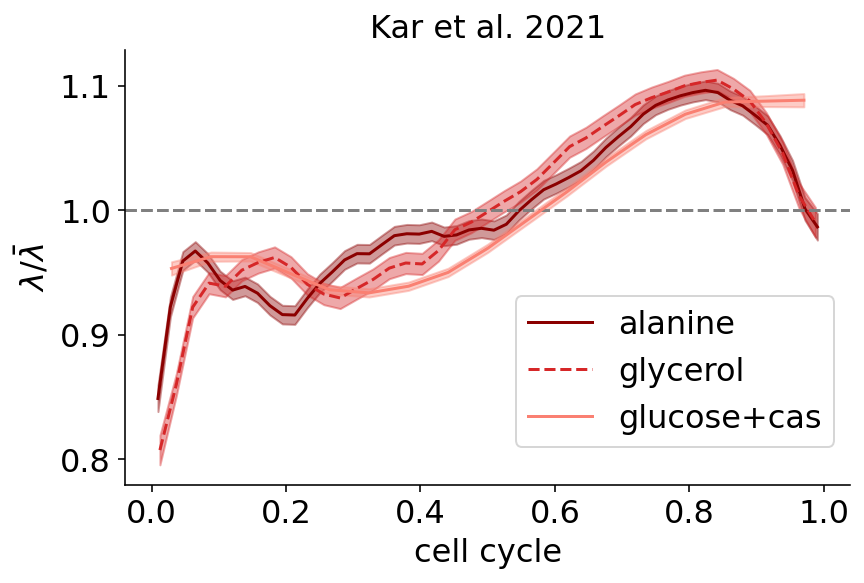

In [3]:
def added_volume_dependence_all_without_cdf(all_filenames,  
                            xlim=[None, None], 
                            ylim=[None, None],
                            hist_xlim=[None, None],
                            outfile=None, 
                            show=True, 
                            norm_q=False, 
                            norm_l=False,
                            plot_scatter=False,
                            plot_all=False,
                            xaxis_parameter="volume",
                            alignment="norm", 
                            growth_rate_unit=60,
                            label="both",
                            title=None,
                            interpolate=None,
                            color_code="condition", 
                            bins=10, 
                            show_cc_corr=False,
                           legend=True):
    
    # fig, ax0 = plt.subplots(1,1, figsize=(FULL_SIZE, FULL_HEIGHT*1.5), sharex=True)
    fig, ax0 = plt.subplots(1,1, figsize=(FULL_SIZE/2,FULL_HEIGHT))

    if "Kar" in all_filenames[0]:
        condis = [file.split("_processed")[0].split("/")[-1] for file in all_filenames]
    if "Kennard" in all_filenames[0]:
        condis = [file.split("_processed")[0].split("/")[-1].split("_")[1] for file in all_filenames] 
    for i, condition in enumerate(condis):
        filenames = [file for file in all_filenames if condition in file.split("/")[-1]]    
                               
        for a in [ax0]:
            a.spines["top"].set_visible(False)
            a.spines["right"].set_visible(False)
            a.spines['right'].set_color('none')
            a.yaxis.tick_left()
            a.spines['top'].set_color('none')
            a.xaxis.tick_bottom()

        longest_cc = []

        for filename in filenames:
            data_set_name = re.split('_f\d', filename.split('/')[-1] )[0]
    
            data = pd.read_csv(filename, skiprows=header_lines(filename))
            cells_data = df2ggp_cells(data)

            collect_mean_l = np.array([])
            collect_var_l = np.array([])

            collect_mean_q = np.array([])
            collect_var_q = np.array([])

            xaxis = np.array([])
            xaxis_cc = np.array([])
            if interpolate!=None:
                if interpolate=="auto":
                    n_d = 0
                    for cell in cells_data:
                        n_d += len(cell.time)
                    n_interpolate=int(n_d/len(cells_data))
                    bins=n_interpolate
                else:
                    n_interpolate = interpolate
                    bins=n_interpolate

            for _, cell in enumerate(cells_data):
                if len(cell.time)<2:
                    continue

                if xaxis_parameter == "volume":
                    single_cell_xaxis = np.exp(cell.mean_x)
                elif xaxis_parameter == "time":
                    single_cell_xaxis = np.array(cell.time)

                if alignment=="norm":                    
                    dx = (single_cell_xaxis -single_cell_xaxis[0])  \
                        / (single_cell_xaxis[-1] - single_cell_xaxis[0]) 

                elif alignment== "birth":
                    dx = single_cell_xaxis - single_cell_xaxis[0]
                else:
                    return

                if interpolate!=None:
                    linspace = np.linspace(dx[0], dx[-1], n_interpolate)
                    cell.mean_l=np.interp(linspace, dx, cell.mean_l)
                    cell.cov_ll=np.interp(linspace, dx, cell.cov_ll)

                    cell.mean_q=np.interp(linspace, dx, cell.mean_q)
                    cell.cov_qq=np.interp(linspace, dx, cell.cov_qq)
                    dx = linspace


                xaxis_cc = np.append(xaxis_cc, single_cell_xaxis[-1] - single_cell_xaxis[0])
                xaxis = np.append(xaxis, dx)

                collect_mean_l = np.append(collect_mean_l, cell.mean_l)
                collect_var_l = np.append(collect_var_l, cell.cov_ll)

                collect_mean_q = np.append(collect_mean_q, cell.mean_q)
                collect_var_q = np.append(collect_var_q, cell.cov_qq)

            mean_l, bin_edges,_ = stats.binned_statistic(xaxis, collect_mean_l,statistic='mean', bins=bins)
            sum_l, _,_   = stats.binned_statistic(xaxis, collect_var_l, statistic='sum', bins=bins)
            count_l, _,_   = stats.binned_statistic(xaxis, collect_var_l, statistic='count', bins=bins)
            std_l = np.sqrt(sum_l / count_l**2)

            if norm_l:
                ax0.axhline(1, color="grey", ls='--')
                normalization_l = np.mean(collect_mean_l)
                mean_l = mean_l/normalization_l
                std_l = std_l/normalization_l
                collect_mean_l/=normalization_l

            if "Kar" in all_filenames[0]:
                label= condition.replace("_", "+")
                color=color_by_condition_Kar[condition]
            if "Kennard" in all_filenames[0]:
                label= condition.replace("Glc", "glycerol")
                color=color_by_condition_Kennard[condition]
            if condition=="glycerol":
                ls ="--"
            else:
                ls="-"
                        
            ax0.plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_l, 
                     label=label, 
                     ls=ls,
                    color=color)
            
            ax0.fill_between(bin_edges[:-1]+np.diff(bin_edges)/2,
                             mean_l+std_l, 
                             mean_l-std_l, 
                             alpha=0.4, 
                             color=color)
            
            if plot_all:
                for _, cell in enumerate(cells_data[:20]):

                    if xaxis_parameter == "volume":
                        single_cell_xaxis = np.exp(cell.mean_x)
                    elif xaxis_parameter == "time":
                        single_cell_xaxis = np.array(cell.time)

                    if alignment=="norm":                    
                        dx = (single_cell_xaxis -single_cell_xaxis[0])  \
                            / (single_cell_xaxis[-1] - single_cell_xaxis[0]) 

                    elif alignment== "birth":
                        dx = single_cell_xaxis - single_cell_xaxis[0]
                    else:
                        return

                    if interpolate!=None:
                        linspace = np.linspace(dx[0], dx[-1], n_interpolate)
                        dx = linspace

                    ax0.plot(dx, cell.mean_l/normalization_l,
                             color="tab:grey", zorder=-10, alpha=0.05)

        ax0.set_ylabel(r"$\lambda/\bar{\lambda}$")   
        ax0.set_xlabel("cell cycle")  

        # if i==0:
        #     # ax1.legend(loc='upper right', bbox_to_anchor=(1,1.1), ncol=2,  title_fontsize=MEDIUM_SIZE)
        #     ax1.legend(loc='center left', bbox_to_anchor=(0.98, 0.5), ncol=1,  title_fontsize=MEDIUM_SIZE)
        # if i==2:
        #     for a in [ax0, ax1]:
        #         a.set_xlabel("cell cycle")  
        #         a.set_xticks(np.arange(0, 1.25, 0.25))
        #         a.set_xticklabels(["0", "1/4", "1/2", "3/4", "1"])
    if "Kar" in all_filenames[0]:
        ax0.set_title("Kar et al. 2021")            
    if "Kennard" in all_filenames[0]:
        ax0.set_title("Kennard et al. 2016")            
    
    ax0.legend(ncol=1, loc="lower right", bbox_to_anchor=(1,0.05))
                

    if outfile != None:
        fig.savefig(outfile.format(xaxis_parameter, alignment), dpi=600, facecolor="white", bbox_inches="tight")
        print("Saved:", outfile)
        plt.show()
        
        plt.close('all')
# ==================================================== #

files_Kar = get_suffix_files("../../data_realtrace_paper/Kar2021/", suffix='prediction.csv') 

added_volume_dependence_all_without_cdf(files_Kar,  
                                outfile=os.path.join("../../figures_for_method_paper/supp/other_ecoli_data/cell_cycle_Kar.pdf" ), 
                                show=False, 
                                norm_l=True, 
                                norm_q=True, 
                                        # plot_all=True,
                                xaxis_parameter="volume",
                                alignment="norm", 
                                interpolate="auto",
                                legend=True)





Saved: ../../figures_for_method_paper/supp/other_ecoli_data/cell_cycle_Kennard.pdf


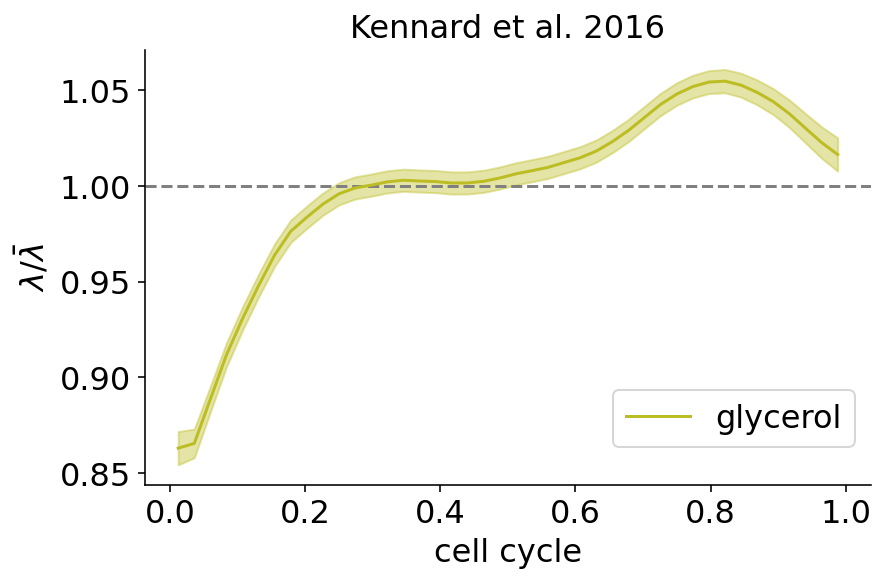

In [4]:
files_Kennard = ['../../data_realtrace_paper/Kennard2016/Data_Glc_P5ori_processed_filter_r2_f8_b0123457_prediction.csv']

added_volume_dependence_all_without_cdf(files_Kennard,  
                                outfile=os.path.join("../../figures_for_method_paper/supp/other_ecoli_data/cell_cycle_Kennard.pdf" ), 
                                show=False, 
                                norm_l=True, 
                                norm_q=True, 
                                        # plot_all=True,
                                xaxis_parameter="volume",
                                alignment="norm", 
                                interpolate="auto",
                                legend=True)


In [5]:

all_files_dany = sorted(find_files("../../data_realtrace_paper/ecoli_data/", ending="prediction.csv"))

promoters_to_plot = ['hi1', 'hi3', 'rplN', 'rrnB']
conditions_to_plot = conditions[:3]

all_files_dany = [file for file in all_files_dany if file.split("/")[-1].split("_")[0] in conditions_to_plot and file.split("/")[-1].split("_")[1] in promoters_to_plot]        
all_files_dany = sort_by_condition(all_files_dany)


In [6]:
### Get rate stats ###

def calc_cv(means, covs=None):
    if np.any(covs==None):
        return np.std(means)/np.mean(means)
    else:
        return np.sqrt(np.sum(np.power(means, 2) + covs)/len(means) - np.mean(means)**2)/np.mean(means)

def calc_std(means, covs=None):
    if np.any(covs==None):
        return np.std(means)
    else:
        return np.sqrt(np.sum(np.power(means, 2) + covs)/len(means) - np.mean(means)**2)
    
def calc_mean(means, covs=None):
    if np.any(covs==None):
        mean = np.mean(means)
    else:
        mean = np.sum(means/covs) /np.sum(1/covs)
    return mean

def estimate_rate_stats(filename):
    
    data_prediction = pd.read_csv(filename, skiprows=header_lines(filename))
    cells_prediction = ggp_df2cells(data_prediction)
    cell_stats = {}
    for i in ["l", "q"]:
        zi = "{:s}t".format(i)
        zi_cov = "cov_{:s}{:s}".format(i, i)

        zi_coll_prediction = np.concatenate([cell.__dict__[zi] for cell in cells_prediction])
        zi_coll_prediction_err = np.concatenate([cell.__dict__[zi_cov] for cell in cells_prediction])
        cell_stats["{:s}_mean".format(i)] = calc_mean(zi_coll_prediction, zi_coll_prediction_err)
        cell_stats["{:s}_cv".format(i)] = calc_cv(zi_coll_prediction, zi_coll_prediction_err)
        cell_stats["{:s}_std".format(i)] = calc_std(zi_coll_prediction, zi_coll_prediction_err)

    cell_stats["q_cv/l_cv"]= cell_stats["q_cv"]/ cell_stats["l_cv"]
    ## Adj. units lambda in 1/h, q in 1000/h
    cell_stats['l_mean']*=60
    cell_stats['l_std']*=60

    cell_stats["l"] = np.concatenate([cell.__dict__['lt'] for cell in cells_prediction])
    
    cell_stats['q_mean']*=60/1000
    cell_stats['q_std']*=60/1000

    sample = "_".join(filename.split("/")[-1].split(".")[0].split("_")[:3])
    cell_stats["sample"]= sample
    
    cell_stats["condition"] = filename.split("/")[-1].split("_")[0]
    cell_stats["promoter"] = filename.split("/")[-1].split("_")[1]
    return cell_stats



cell_stats = {}
for file in files_Kar :
    data_set_name = file.split("/")[-1].split("_processed")[0]
    print("|", end="")
    cell_stats[data_set_name] = estimate_rate_stats(file)
    cell_stats[data_set_name]["source"] = "Kar et al. 2021"

for file in files_Kennard :
    data_set_name = file.split("/")[-1].split("_processed")[0].split("_")[1]
    print("|", end="")
    cell_stats[data_set_name] = estimate_rate_stats(file)
    cell_stats[data_set_name]["source"] = "Kennard et al. 2016"

    
for file in  all_files_dany :
    data_set_name = file.split("/")[-1].split("_rawdata")[0].split("_20")[0]
    print("|", end="")
    cell_stats[data_set_name] = estimate_rate_stats(file)
    cell_stats[data_set_name]["source"] = "this study"


||||||||||||||||

In [7]:
cell_stats.keys()

dict_keys(['alanine', 'glycerol', 'glucose_cas', 'Glc', 'acetate005_hi1', 'acetate005_hi3', 'acetate005_rplN', 'acetate005_rrnB', 'glycerol040_hi1', 'glycerol040_hi3', 'glycerol040_rplN', 'glycerol040_rrnB', 'glucose020_hi1', 'glucose020_hi3', 'glucose020_rplN', 'glucose020_rrnB'])

Saved in ../../figures_for_method_paper/supp/other_ecoli_data/supp_CV_other_ecoli.pdf


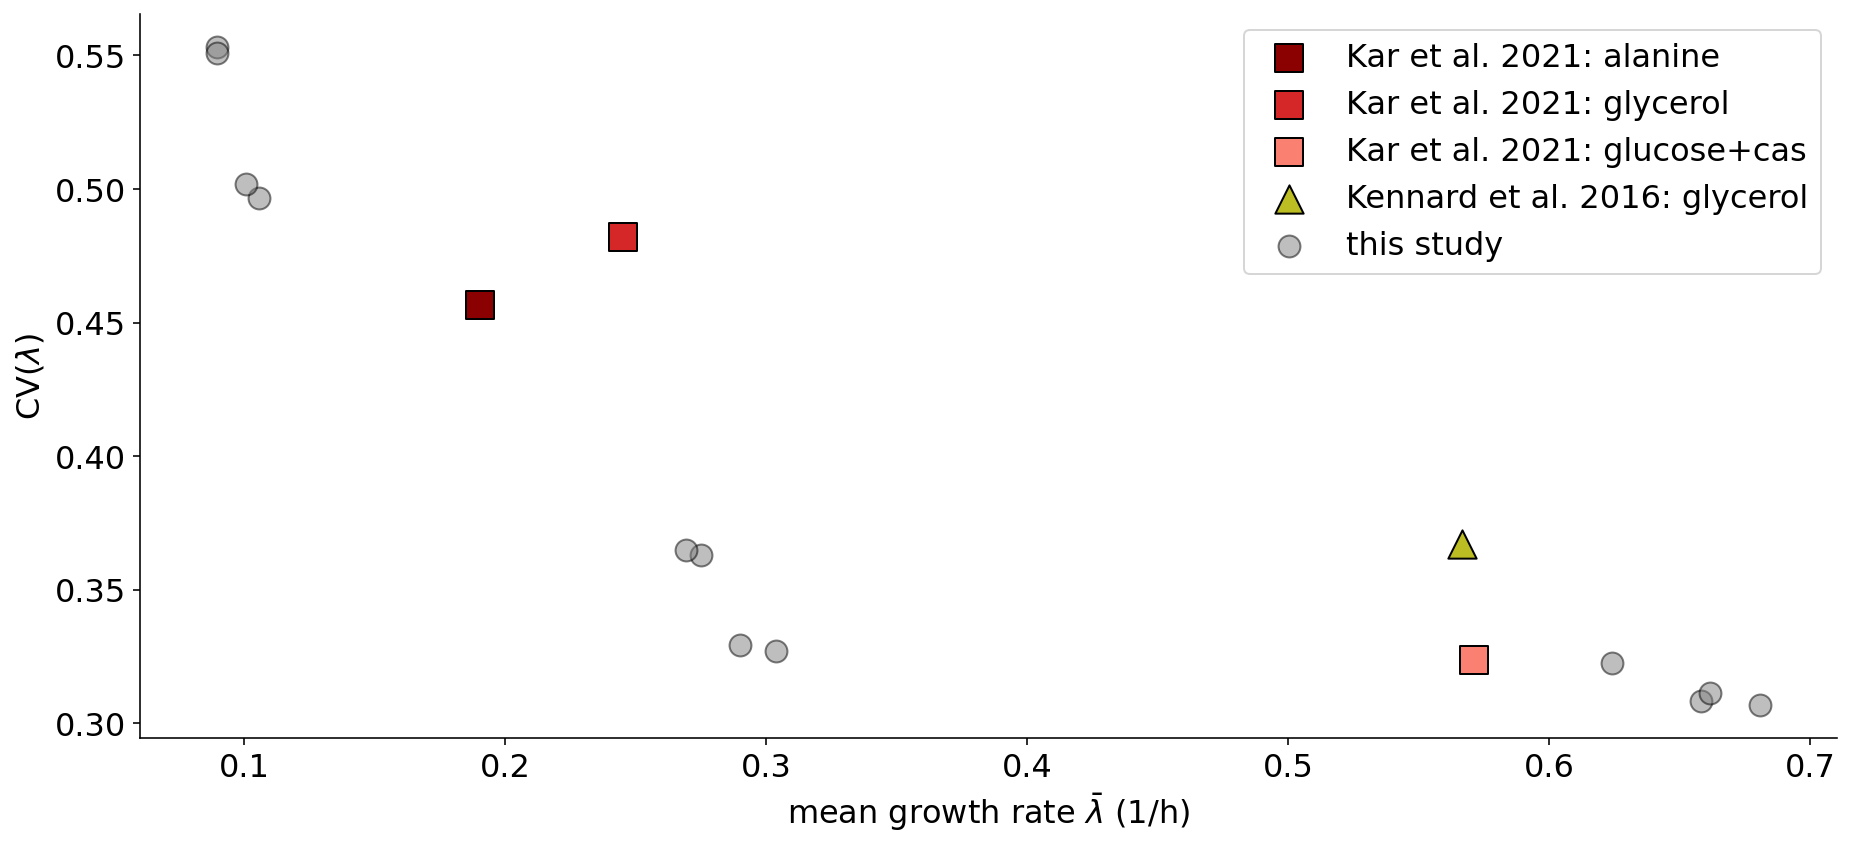

In [8]:

def plot_growth_rate_stats(cell_stats, plot_file=None, color_scheme =None):
    fig, ax = plt.subplots(1,1, figsize=(FULL_SIZE,FULL_HEIGHT*1.5))
    
    for a in [ax]:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
    
    days = {}
    color_i = 0
    ax.set_xlabel(r"mean growth rate $\bar{\lambda}$ (1/h)")
    ax.set_ylabel(r"CV($\lambda$)")
    for k in cell_stats.keys():    
        if cell_stats[k]["source"]=="this study":
            color="tab:grey"
            label=None
            alpha=0.5
            s=120
            marker="o"
            label="this study"
            
        elif cell_stats[k]["source"]=="Kar et al. 2021":
            condition = k
            color=color=color_by_condition_Kar[condition]
            label=cell_stats[k]["source"] +": "+ condition.replace("_", "+")
            alpha=1
            s=200
            marker="s" 
            
        elif cell_stats[k]["source"]=="Kennard et al. 2016":
            condition = k
            color=color=color_by_condition_Kennard[condition]
            alpha=1
            label = cell_stats[k]["source"] +": "+ condition.replace("Glc", "glycerol")
            s=200
            marker="^"  
            
        ax.scatter(cell_stats[k]["l_mean"], cell_stats[k]["l_cv"], 
                    s=s,
                   marker=marker,
                   color=color,
                    ec="black", 
                      label=label, 
                  alpha=alpha)
    ax.yaxis.set_minor_locator(matplotlib.ticker.MultipleLocator(base=0.05))
    

    ax.legend(*legend_without_duplicate_labels(ax), 
            loc='upper right', 
            bbox_to_anchor=(1, 1), 
            ncol=1)
    

    plt.tight_layout()

    if plot_file != None:
        print("Saved in", plot_file)
        fig.savefig(plot_file, dpi=300, facecolor="white", bbox_inches="tight")
        plt.show()

    
    plt.show()
    


plot_growth_rate_stats(cell_stats,
                       plot_file=os.path.join("../../figures_for_method_paper/supp/other_ecoli_data/supp_CV_other_ecoli.pdf")) 



Saved in ../../figures_for_method_paper/supp/other_ecoli_data/supp_hist_other_ecoli.pdf


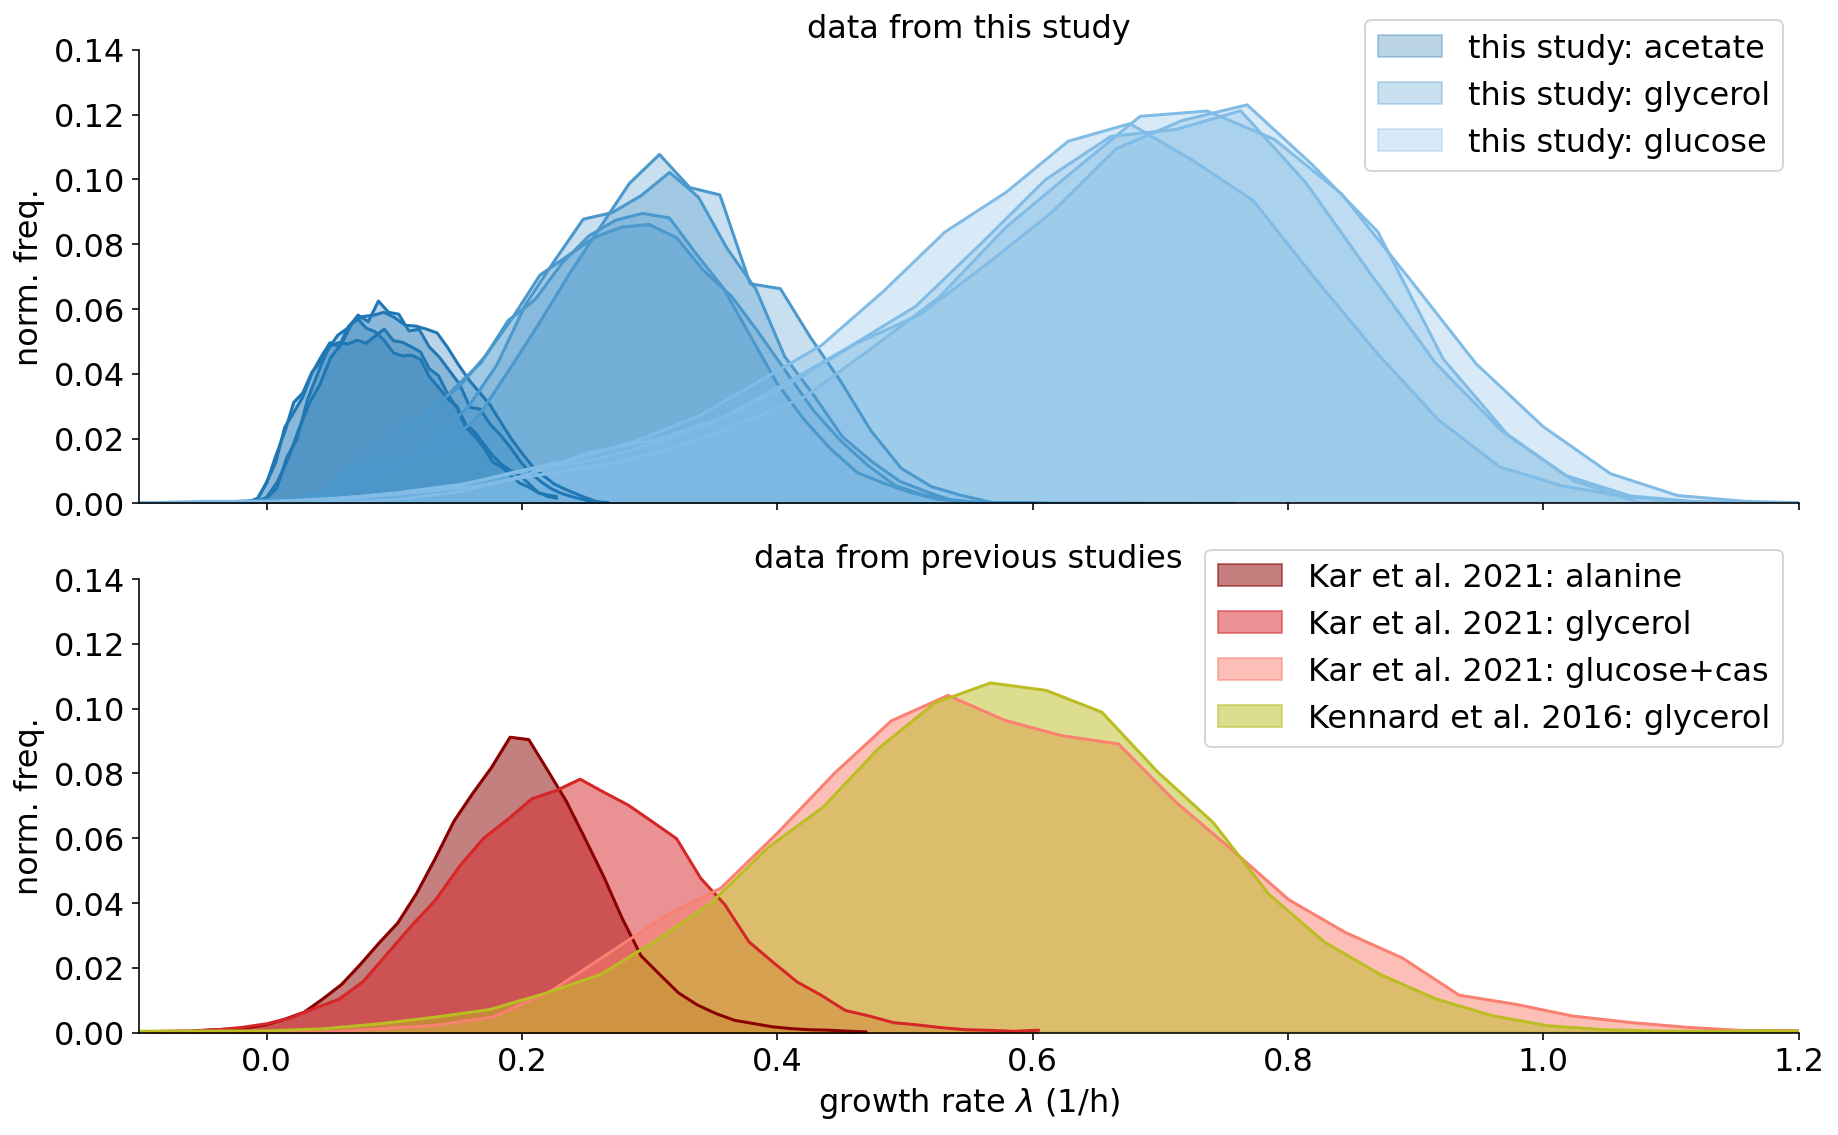

In [10]:


def bin_arr(means, n_bins=1000, return_edges=True, ignore_errors=False):
    if return_edges:
        return np.histogram(means, bins=n_bins)
    else:
        w, e = np.histogram(means, bins=n_bins)
        return w, e[:-1]+np.diff(e)/2.
    

def plot_growth_hists(cell_stats, plot_file=None):

    fig, ax = plt.subplots(2,1, figsize=(FULL_SIZE,FULL_HEIGHT*2), sharex=True)

    for a in ax.ravel():
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        a.set_ylim(0,0.14)
        # a.set_xlim(-0.2,2.2)
        a.set_ylabel(r"norm. freq.")

    ax[-1].set_xlabel(r"growth rate $\lambda$ (1/h)")

    for k in cell_stats.keys():    
        if cell_stats[k]["source"]=="this study":
            condition = k.split("_")[0]
            color=color_by_condition[condition]
            label=None
            alpha=0.3
            s=120
            marker="o"
            label = cell_stats[k]["source"] +": "+ label_by_condition[condition]
            a=ax[0]
            title = 'data from this study'
            
        elif cell_stats[k]["source"]=="Kar et al. 2021":
            condition = k
            color=color=color_by_condition_Kar[condition]
            label=cell_stats[k]["source"] +": "+ condition.replace("_", "+")
            alpha=0.5
            s=180
            marker="s" 
            a=ax[1]
            title = "data from previous studies"
            
        elif cell_stats[k]["source"]=="Kennard et al. 2016":
            condition = k
            color=color=color_by_condition_Kennard[condition]
            alpha=0.5
            label = cell_stats[k]["source"] +": "+ condition.replace("Glc", "glycerol")
            marker="^" 
            a=ax[1]
            title = "data from previous studies"
            
        # a.set_title(cell_stats[k]["source"])
        norm_l = cell_stats[k]['l']/np.mean( cell_stats[k]['l'])
        weight, bin_c = bin_arr(norm_l, return_edges=False, n_bins=np.linspace(-0.5, 2.5,40))
        weight= np.array(weight)/np.sum(weight)
        a.fill_between(bin_c*np.mean( cell_stats[k]['l'])*60, weight, 
                              color=color, alpha=alpha, label=label)
        a.plot(bin_c*np.mean( cell_stats[k]['l'])*60, weight, 
                              color=color, alpha=1)

        a.legend(*legend_without_duplicate_labels(a), 
            loc='upper right', 
            bbox_to_anchor=(1, 1.1), 
            ncol=1)
        a.set_title(title)
        
    ax[0].set_xlim(-0.1, 1.2)
    plt.tight_layout()

    if plot_file != None:
        print("Saved in", plot_file)
        fig.savefig(plot_file,  bbox_inches="tight")
        plt.show()

    
    plt.show()
        
plot_growth_hists(cell_stats,
                  plot_file=os.path.join("../../figures_for_method_paper/supp/other_ecoli_data/supp_hist_other_ecoli.pdf")) 

